# NC Housing Data Integration

This notebook brings together housing, income, built-environment, and
amenity data for our North Carolina housing recommendation system.

We will check the available tables, geographic units, boundary years,
and coordinate systems before combining them. The goal is one table
per housing area, with housing characteristics and accessibility features.

Amenity locations will be connected geographically. ZIP codes and census
tracts cannot be merged directly, and tract IDs from different boundary
years may require a crosswalk.

In [12]:
from pathlib import Path

import pandas as pd
import geopandas as gpd

DATA_DIR = Path("data")
PROCESSED_DIR = DATA_DIR / "processed"

print("Working directory:", Path.cwd())

if not PROCESSED_DIR.exists():
    raise FileNotFoundError(
        f"Cannot find {PROCESSED_DIR.resolve()}. "
        "Run this notebook from the project folder."
    )

Working directory: c:\Users\kyleh\OneDrive\Desktop\final_group_project\2302-group-proj


In [13]:
# Read geographic IDs as text to preserve leading zeros
acs_nc = pd.read_csv(
    PROCESSED_DIR / "nc_acs_2024_tract_clean.csv",
    dtype={
        "GEOID": "string",
        "state": "string",
        "county": "string",
        "tract": "string"
    }
)

epa_nc = pd.read_csv(
    PROCESSED_DIR / "nc_epa_2010_tract_clean.csv",
    dtype={"tract": "string"}
)

zillow_nc = pd.read_csv(
    PROCESSED_DIR / "nc_zillow_zip_clean.csv",
    dtype={"zip": "string"}
)

housing_zip_nc = pd.read_csv(
    PROCESSED_DIR / "nc_zillow_epa_zip_clean.csv",
    dtype={"zip": "string"}
)

# Check row counts and unique geographic IDs
tables = {
    "ACS 2024 tracts": (acs_nc, "GEOID"),
    "EPA 2010 tracts": (epa_nc, "tract"),
    "Zillow ZIPs": (zillow_nc, "zip"),
    "Zillow + EPA ZIPs": (housing_zip_nc, "zip")
}

checks = []

for name, (df, id_col) in tables.items():
    checks.append({
        "dataset": name,
        "rows": len(df),
        "missing_ids": df[id_col].isna().sum(),
        "duplicate_ids": df[id_col].duplicated().sum()
    })

display(pd.DataFrame(checks))

for name, (df, _) in tables.items():
    print(f"\n{name} columns:")
    print(df.columns.tolist())

,dataset,rows,missing_ids,duplicate_ids
0,ACS 2024 tracts,2672,0,0
1,EPA 2010 tracts,2171,0,0
2,Zillow ZIPs,719,0,0
3,Zillow + EPA ZIPs,717,0,0



ACS 2024 tracts columns:
['GEOID', 'NAME', 'state', 'county', 'tract', 'median_hh_income', 'median_gross_rent', 'rent_pct_income', 'median_home_value', 'median_monthly_housing_cost', 'median_hh_income_moe', 'total_population', 'occupied_units', 'owner_units', 'renter_units']

EPA 2010 tracts columns:
['tract', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']

Zillow ZIPs columns:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo']

Zillow + EPA ZIPs columns:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']


In [14]:
tables = {
    "ACS 2024 tracts": (acs_nc, "GEOID"),
    "EPA 2010 tracts": (epa_nc, "tract"),
    "Zillow ZIPs": (zillow_nc, "zip"),
    "Zillow + EPA ZIPs": (housing_zip_nc, "zip")
}

checks = []

for name, (df, id_col) in tables.items():
    checks.append({
        "dataset": name,
        "rows": len(df),
        "missing_ids": df[id_col].isna().sum(),
        "duplicate_ids": df[id_col].duplicated().sum()
    })

display(pd.DataFrame(checks))

for name, (df, _) in tables.items():
    print(f"\n{name}:")
    print(df.columns.tolist())

,dataset,rows,missing_ids,duplicate_ids
0,ACS 2024 tracts,2672,0,0
1,EPA 2010 tracts,2171,0,0
2,Zillow ZIPs,719,0,0
3,Zillow + EPA ZIPs,717,0,0



ACS 2024 tracts:
['GEOID', 'NAME', 'state', 'county', 'tract', 'median_hh_income', 'median_gross_rent', 'rent_pct_income', 'median_home_value', 'median_monthly_housing_cost', 'median_hh_income_moe', 'total_population', 'occupied_units', 'owner_units', 'renter_units']

EPA 2010 tracts:
['tract', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']

Zillow ZIPs:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo']

Zillow + EPA ZIPs:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']


In [15]:
import requests

BOUNDARY_DIR = DATA_DIR / "raw" / "boundaries"
BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)

boundary_urls = {
    "tracts": (
        "https://www2.census.gov/geo/tiger/"
        "TIGER2024/TRACT/tl_2024_37_tract.zip"
    ),
    "zctas": (
        "https://www2.census.gov/geo/tiger/"
        "TIGER2024/ZCTA520/tl_2024_us_zcta520.zip"
    )
}

boundary_paths = {}

for name, url in boundary_urls.items():
    path = BOUNDARY_DIR / url.rsplit("/", 1)[-1]

    if not path.exists():
        print(f"Downloading {name}...")
        temporary_path = path.with_suffix(".part")

        with requests.get(url, stream=True, timeout=(30, 180)) as response:
            response.raise_for_status()

            with temporary_path.open("wb") as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)

        temporary_path.replace(path)

    boundary_paths[name] = path

tract_boundaries = gpd.read_file(
    f"zip://{boundary_paths['tracts'].resolve().as_posix()}",
    engine="pyogrio"
)

# Both source files use the same coordinate system.
# Read only ZCTAs within NC's bounding box, including border overlaps.
zcta_boundaries = gpd.read_file(
    f"zip://{boundary_paths['zctas'].resolve().as_posix()}",
    bbox=tuple(tract_boundaries.total_bounds),
    engine="pyogrio"
)

print(f"NC tract boundaries: {len(tract_boundaries):,}")
print(f"Nearby ZCTA boundaries: {len(zcta_boundaries):,}")

NC tract boundaries: 2,672
Nearby ZCTA boundaries: 1,473


In [17]:
# Keep the IDs and geometry
tract_shapes = tract_boundaries[
    ["GEOID", "geometry"]
].copy()

zcta_shapes = zcta_boundaries[
    ["ZCTA5CE20", "geometry"]
].rename(columns={"ZCTA5CE20": "zcta"}).copy()

tract_shapes["GEOID"] = tract_shapes["GEOID"].astype("string")
zcta_shapes["zcta"] = zcta_shapes["zcta"].astype("string")

# Use NC State Plane so area calculations are in square meters
tract_shapes = tract_shapes.to_crs("EPSG:32119")
zcta_shapes = zcta_shapes.to_crs("EPSG:32119")

# Create a polygon for each tract–ZCTA overlap
overlap_areas = gpd.overlay(
    tract_shapes,
    zcta_shapes,
    how="intersection",
    keep_geom_type=True
)

# Group disconnected pieces with the same tract and ZCTA IDs
overlap_areas = overlap_areas.dissolve(
    by=["GEOID", "zcta"],
    as_index=False
)

overlap_areas["area_id"] = (
    overlap_areas["GEOID"] + "_" + overlap_areas["zcta"]
)

overlap_areas["area_sq_km"] = (
    overlap_areas.geometry.area / 1_000_000
)

print(f"Created {len(overlap_areas):,} tract–ZCTA areas.")

display(
    overlap_areas[
        ["area_id", "GEOID", "zcta", "area_sq_km"]
    ].head()
)

Created 5,466 tract–ZCTA areas.


,area_id,GEOID,zcta,area_sq_km
0,37001020100_27215,37001020100,27215,4.061674
1,37001020100_27217,37001020100,27217,0.449831
2,37001020200_27217,37001020200,27217,3.464568
3,37001020301_27217,37001020301,27217,5.025703
4,37001020302_27217,37001020302,27217,4.276168


In [18]:
acs_attributes = acs_nc.rename(
    columns={c: f"acs_{c}" for c in acs_nc.columns if c != "GEOID"}
)

zillow_attributes = zillow_nc.rename(
    columns={c: f"zillow_{c}" for c in zillow_nc.columns if c != "zip"}
)

integrated_areas = overlap_areas.merge(
    acs_attributes,
    on="GEOID",
    how="left",
    validate="many_to_one",
    indicator="acs_match"
)

integrated_areas = integrated_areas.merge(
    zillow_attributes,
    left_on="zcta",
    right_on="zip",
    how="left",
    validate="many_to_one",
    indicator="zillow_match"
)

display(
    integrated_areas.groupby(
        ["acs_match", "zillow_match"],
        observed=True
    ).size().reset_index(name="areas")
)

# Convert merge indicators to text before saving
for column in ["acs_match", "zillow_match"]:
    integrated_areas[column] = integrated_areas[column].astype("string")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

integrated_areas.to_file(
    PROCESSED_DIR / "nc_tract_zcta_housing.gpkg",
    layer="tract_zcta_housing",
    driver="GPKG",
    engine="pyogrio"
)

print(f"Saved {len(integrated_areas):,} integrated areas.")

,acs_match,zillow_match,areas
0,both,left_only,187
1,both,both,5279


Saved 5,466 integrated areas.


In [19]:
display(
    integrated_areas["area_sq_km"]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95])
    .to_frame("area_sq_km")
)

print(
    "Areas smaller than 1,000 square meters:",
    integrated_areas["area_sq_km"].lt(0.001).sum()
)

print(
    "Unique ACS tracts represented:",
    integrated_areas["GEOID"].nunique()
)

print(
    "Unique ZCTAs represented:",
    integrated_areas["zcta"].nunique()
)

,area_sq_km
count,5466.000000
mean,23.934759
std,44.751370
min,0.000276
1%,0.036442
5%,0.232611
50%,7.805088
95%,100.149149
max,943.989275


Areas smaller than 1,000 square meters: 4
Unique ACS tracts represented: 2661
Unique ZCTAs represented: 853


In [20]:
print(
    "Areas smaller than 1,000 square meters:",
    integrated_areas["area_sq_km"].lt(0.001).sum()
)

print(
    "Unique ACS tracts represented:",
    integrated_areas["GEOID"].nunique(),
    "out of",
    acs_nc["GEOID"].nunique()
)

print(
    "Unique ZCTAs represented:",
    integrated_areas["zcta"].nunique()
)

Areas smaller than 1,000 square meters: 4
Unique ACS tracts represented: 2661 out of 2672
Unique ZCTAs represented: 853


In [21]:
# Find ACS tracts that have no polygon in the overlap table
missing_tracts = acs_nc.loc[
    ~acs_nc["GEOID"].isin(integrated_areas["GEOID"]),
    ["GEOID", "NAME", "total_population", "occupied_units"]
].copy()

display(missing_tracts)

,GEOID,NAME,total_population,occupied_units
327,37031980100,Census Tract 9801; Carteret County; North Caro...,0,0
328,37031990100,Census Tract 9901; Carteret County; North Caro...,0,0
329,37031990200,Census Tract 9902; Carteret County; North Caro...,0,0
564,37053990100,Census Tract 9901; Currituck County; North Car...,0,0
575,37055990100,Census Tract 9901; Dare County; North Carolina,0,0
576,37055990200,Census Tract 9902; Dare County; North Carolina,0,0
1197,37095990100,Census Tract 9901; Hyde County; North Carolina,0,0
1198,37095990200,Census Tract 9902; Hyde County; North Carolina,0,0
1823,37129990100,Census Tract 9901; New Hanover County; North C...,0,0
1928,37137990100,Census Tract 9901; Pamlico County; North Carolina,0,0


### Geographic coverage check

The tract–ZCTA intersection produced 5,466 areas covering 2,661
of the 2,672 ACS tracts. The 11 unmatched tracts all have zero
reported population and zero occupied housing units.

All overlap areas were retained, including four smaller than
1,000 square meters. Of the resulting areas, 5,279 matched a
Zillow ZIP record and 187 did not. Unmatched Zillow values
remain missing.

ACS and Zillow statistics describe their original parent areas,
not measurements taken separately within each overlap polygon.

In [22]:
# Download NC's 2010 census tract boundaries
epa_boundary_url = (
    "https://www2.census.gov/geo/tiger/"
    "TIGER2010/TRACT/2010/tl_2010_37_tract10.zip"
)

epa_boundary_path = BOUNDARY_DIR / "tl_2010_37_tract10.zip"

if not epa_boundary_path.exists():
    temporary_path = epa_boundary_path.with_suffix(".part")

    with requests.get(
        epa_boundary_url,
        stream=True,
        timeout=(30, 180)
    ) as response:
        response.raise_for_status()

        with temporary_path.open("wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)

    temporary_path.replace(epa_boundary_path)

tracts_2010 = gpd.read_file(
    f"zip://{epa_boundary_path.resolve().as_posix()}",
    engine="pyogrio"
)

# Keep the older tract ID distinct from the ACS tract ID
epa_shapes = (
    tracts_2010[["GEOID10", "geometry"]]
    .rename(columns={"GEOID10": "epa_tract"})
    .to_crs(integrated_areas.crs)
)

epa_shapes["epa_tract"] = epa_shapes["epa_tract"].astype("string")

# Check whether every EPA record has a matching boundary
unmatched_epa = epa_nc.loc[
    ~epa_nc["tract"].isin(epa_shapes["epa_tract"])
]

print(f"2010 tract boundaries: {len(epa_shapes):,}")
print(f"EPA records: {len(epa_nc):,}")
print(f"EPA records without a boundary: {len(unmatched_epa):,}")

if not unmatched_epa.empty:
    display(unmatched_epa[["tract"]])

2010 tract boundaries: 2,195
EPA records: 2,171
EPA records without a boundary: 0


In [23]:
# Prefix EPA variables and preserve its original tract ID
epa_attributes = epa_nc.rename(
    columns={
        c: "epa_tract" if c == "tract" else f"epa_{c}"
        for c in epa_nc.columns
    }
)

epa_geography = epa_shapes.merge(
    epa_attributes,
    on="epa_tract",
    how="left",
    validate="one_to_one",
    indicator="epa_match"
)

epa_geography["epa_match"] = (
    epa_geography["epa_match"].astype("string")
)

# Keep the original area ID as a reference.
# Recalculate area after splitting.
base_areas = integrated_areas.rename(
    columns={"area_id": "parent_area_id"}
).drop(columns=["area_sq_km"])

# Identity preserves portions without a matching 2010 boundary
integrated_epa = gpd.overlay(
    base_areas,
    epa_geography,
    how="identity",
    keep_geom_type=True
)

integrated_epa["epa_match"] = (
    integrated_epa["epa_match"].fillna("no_boundary")
)

# Each row is a polygon piece with its source-area attributes
integrated_epa = integrated_epa.reset_index(drop=True)

integrated_epa["area_id"] = (
    "NC_" + integrated_epa.index.astype(str).str.zfill(7)
)

integrated_epa["area_sq_km"] = (
    integrated_epa.geometry.area / 1_000_000
)

print(f"Original tract–ZCTA areas: {len(integrated_areas):,}")
print(f"Areas after EPA overlay: {len(integrated_epa):,}")

display(
    integrated_epa.groupby("epa_match")
    .agg(
        areas=("area_id", "size"),
        total_sq_km=("area_sq_km", "sum")
    )
    .reset_index()
)

print(
    "Original areas preserved:",
    integrated_epa["parent_area_id"].nunique(),
    "out of",
    integrated_areas["area_id"].nunique()
)

print(
    "Pieces smaller than 1,000 square meters:",
    integrated_epa["area_sq_km"].lt(0.001).sum()
)

Original tract–ZCTA areas: 5,466
Areas after EPA overlay: 23,768


,epa_match,areas,total_sq_km
0,both,20809,129097.104325
1,left_only,166,1720.609118
2,no_boundary,2793,9.680871


Original areas preserved: 5466 out of 5466
Pieces smaller than 1,000 square meters: 14417


In [24]:
# Total overlapping area for each original area and EPA tract
epa_overlap = (
    integrated_epa.dropna(subset=["epa_tract"])
    .groupby(["parent_area_id", "epa_tract"], as_index=False)
    .agg(epa_overlap_sq_km=("area_sq_km", "sum"))
)

# Select the EPA tract covering the largest portion of each area
dominant_epa = (
    epa_overlap
    .sort_values(
        ["parent_area_id", "epa_overlap_sq_km", "epa_tract"],
        ascending=[True, False, True]
    )
    .drop_duplicates("parent_area_id")
    .rename(columns={"parent_area_id": "area_id"})
)

# Keep the original polygons and attach the selected EPA tract
housing_epa_areas = integrated_areas.merge(
    dominant_epa,
    on="area_id",
    how="left",
    validate="one_to_one"
)

housing_epa_areas["epa_overlap_share"] = (
    housing_epa_areas["epa_overlap_sq_km"]
    / housing_epa_areas["area_sq_km"]
)

housing_epa_areas = housing_epa_areas.merge(
    epa_attributes,
    on="epa_tract",
    how="left",
    validate="many_to_one",
    indicator="epa_data_match"
)

print(f"Areas retained: {len(housing_epa_areas):,}")

display(
    housing_epa_areas["epa_overlap_share"]
    .describe(percentiles=[0.05, 0.5, 0.95])
    .to_frame()
)

print(
    "Areas with less than 90% dominant EPA coverage:",
    housing_epa_areas["epa_overlap_share"].lt(0.90).sum()
)

display(
    housing_epa_areas["epa_data_match"]
    .value_counts()
    .rename_axis("match")
    .reset_index(name="areas")
)

Areas retained: 5,466


,epa_overlap_share
count,5466.000000
mean,0.994525
std,0.029053
min,0.511618
5%,0.981325
50%,0.999958
95%,1.000000
max,1.000000


Areas with less than 90% dominant EPA coverage: 60


,match,areas
0,both,5442
1,left_only,24
2,right_only,0


In [25]:
# Flag areas where the selected EPA tract covers less than 90%
housing_epa_areas["epa_low_overlap"] = (
    housing_epa_areas["epa_overlap_share"].lt(0.90)
)

housing_epa_areas["epa_assignment_method"] = "largest_area_overlap"

# Convert the merge indicator before saving
housing_epa_areas["epa_data_match"] = (
    housing_epa_areas["epa_data_match"].astype("string")
)

housing_epa_areas.to_file(
    PROCESSED_DIR / "nc_housing_epa_integrated.gpkg",
    layer="housing_epa",
    driver="GPKG",
    engine="pyogrio"
)

print(f"Saved {len(housing_epa_areas):,} integrated areas.")

Saved 5,466 integrated areas.


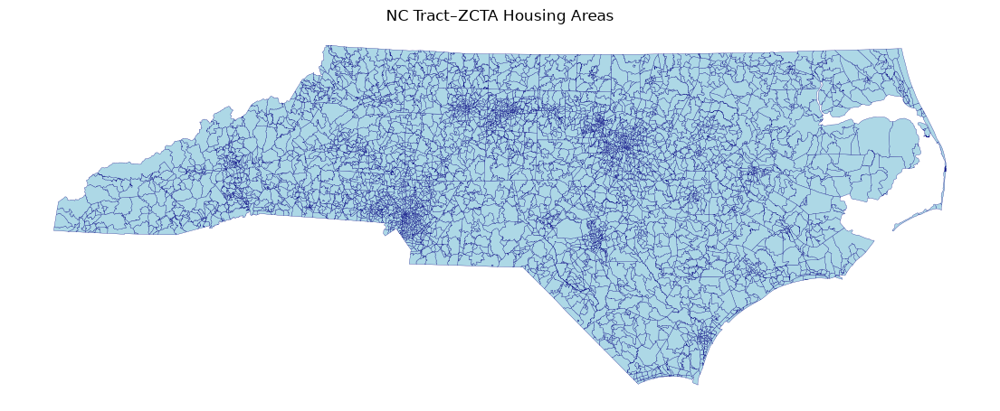

In [32]:
import matplotlib.pyplot as plt

housing_epa_areas.plot(
    figsize=(14, 8),
    facecolor="lightblue",
    edgecolor="navy",
    linewidth=0.2
)

plt.title("NC Tract–ZCTA Housing Areas")
plt.axis("off")
plt.show()

In [30]:
%pip install folium


   -------------------- ------------------- 1/2 [folium]
   -------------------- ------------------- 1/2 [folium]
   ---------------------------------------- 2/2 [folium]

Note: you may need to restart the kernel to use updated packages.


In [31]:
import folium

# Use a simplified copy for display.
# The saved area dataset keeps its original geometry.
map_areas = housing_epa_areas[
    ["area_id", "GEOID", "zcta", "epa_tract",
     "epa_overlap_share", "geometry"]
].copy()

map_areas["epa_overlap_pct"] = (
    map_areas["epa_overlap_share"] * 100
).round(1)

map_areas["geometry"] = map_areas.geometry.simplify(
    tolerance=20,
    preserve_topology=True
)

map_areas = map_areas.to_crs("EPSG:4326")

area_map = folium.Map(
    location=[35.5, -79.8],
    zoom_start=7,
    tiles="CartoDB positron"
)

folium.GeoJson(
    map_areas.to_json(),
    name="Tract–ZCTA housing areas",
    style_function=lambda feature: {
        "fillColor": "#3182bd",
        "color": "#18466a",
        "weight": 0.7,
        "fillOpacity": 0.18
    },
    highlight_function=lambda feature: {
        "fillColor": "#ffb347",
        "fillOpacity": 0.6,
        "weight": 2
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "area_id", "GEOID", "zcta",
            "epa_tract", "epa_overlap_pct"
        ],
        aliases=[
            "Area ID:",
            "ACS tract:",
            "ZCTA:",
            "Assigned EPA tract:",
            "EPA overlap (%):"
        ],
        localize=True
    )
).add_to(area_map)

west, south, east, north = map_areas.total_bounds
area_map.fit_bounds([[south, west], [north, east]])

map_path = PROCESSED_DIR / "nc_integrated_areas_map.html"
area_map.save(str(map_path))

print(f"Map saved to: {map_path.resolve()}")

display(area_map)

Map saved to: C:\Users\kyleh\OneDrive\Desktop\final_group_project\2302-group-proj\data\processed\nc_integrated_areas_map.html


In [26]:
amenity_files = {
    "osm_amenities": ("osm_amenities_clean.gpkg", "amenities"),
    "padus_open": ("padus_open_clean.gpkg", "open_access_land"),
    "coastal_access": ("nc_coastal_access_clean.gpkg", "coastal_access"),
    "transport_access": ("nc_rail_and_bus_access.gpkg", "transport_access"),
    "airport_candidates": ("nc_airport_candidates.gpkg", "airport_candidates")
}

amenity_tables = {}

for name, (filename, layer) in amenity_files.items():
    df = gpd.read_file(
        PROCESSED_DIR / filename,
        layer=layer,
        engine="pyogrio"
    )

    amenity_tables[name] = df.to_crs(housing_epa_areas.crs)

display(
    pd.DataFrame([
        {
            "dataset": name,
            "records": len(df),
            "missing_or_empty_geometry": (
                df.geometry.isna() | df.geometry.is_empty
            ).sum(),
            "invalid_geometry": (
                df.geometry.notna()
                & ~df.geometry.is_empty
                & ~df.geometry.is_valid
            ).sum()
        }
        for name, df in amenity_tables.items()
    ])
)

# Inspect the groups available for amenity features
osm_amenities = amenity_tables["osm_amenities"]

display(
    osm_amenities["amenity_group"]
    .value_counts(dropna=False)
    .rename_axis("amenity_group")
    .reset_index(name="records")
)

,dataset,records,missing_or_empty_geometry,invalid_geometry
0,osm_amenities,60273,0,0
1,padus_open,2830,0,32
2,coastal_access,911,0,0
3,transport_access,27,0,0
4,airport_candidates,9,0,0


,amenity_group,records
0,sports_and_fitness,27656
1,food_and_nightlife,15370
2,outdoor_recreation,10071
3,shopping_and_daily_needs,5795
4,entertainment_and_culture,1381


In [27]:
padus_open = amenity_tables["padus_open"].copy()

invalid = ~padus_open.geometry.is_valid
padus_open.loc[invalid, "geometry"] = (
    padus_open.loc[invalid, "geometry"].make_valid()
)

amenity_tables["padus_open"] = padus_open

print("Invalid PAD-US geometries remaining:",
      (~padus_open.geometry.is_valid).sum())

Invalid PAD-US geometries remaining: 0


In [28]:
# Use one point inside each housing area.
# This is a reference location, not necessarily where residents live.
area_points = housing_epa_areas[["area_id", "geometry"]].copy()
area_points["geometry"] = area_points.geometry.representative_point()

# Represent each mapped amenity record with one point
amenity_points = osm_amenities[
    ["amenity_group", "geometry"]
].copy()

amenity_points["geometry"] = (
    amenity_points.geometry.representative_point()
)

# Create a 5 km search area around each housing reference point
search_areas = area_points.copy()
search_areas["geometry"] = search_areas.geometry.buffer(5000)

nearby = gpd.sjoin(
    amenity_points,
    search_areas,
    how="inner",
    predicate="intersects"
)

# Count mapped records by area and amenity group
groups = sorted(amenity_points["amenity_group"].dropna().unique())

amenity_counts = (
    nearby.groupby(["area_id", "amenity_group"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=housing_epa_areas["area_id"],
        columns=groups,
        fill_value=0
    )
    .fillna(0)
    .astype(int)
)

amenity_counts.columns = [
    f"osm_{group}_within_5km"
    for group in amenity_counts.columns
]

amenity_counts = amenity_counts.reset_index()

display(
    amenity_counts.drop(columns="area_id")
    .describe()
    .round(1)
)

,osm_entertainment_and_culture_within_5km,osm_food_and_nightlife_within_5km,osm_outdoor_recreation_within_5km,osm_shopping_and_daily_needs_within_5km,osm_sports_and_fitness_within_5km
count,5466.0,5466.0,5466.0,5466.0,5466.0
mean,3.6,52.3,25.4,14.5,70.1
std,7.5,100.7,39.9,20.2,98.7
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,1.0,1.0,1.0,4.0
50%,1.0,11.0,8.0,5.0,26.0
75%,3.0,58.0,32.8,21.0,97.0
max,51.0,742.0,246.0,117.0,564.0


In [33]:
housing_features = housing_epa_areas.merge(
    amenity_counts,
    on="area_id",
    how="left",
    validate="one_to_one"
)

print(f"Areas with amenity features: {len(housing_features):,}")

Areas with amenity features: 5,466


In [34]:
coastal = amenity_tables["coastal_access"]
transport = amenity_tables["transport_access"]
airports = amenity_tables["airport_candidates"]

destinations = {
    "beach_access": coastal.loc[
        coastal["access_type_clean"].eq("Beach")
    ],
    "shoreline_access": coastal.loc[
        coastal["access_type_clean"].eq("Shoreline")
    ],
    "passenger_rail": transport.loc[
        transport["access_mode"].eq("passenger_rail")
    ],
    "amtrak_bus": transport.loc[
        transport["access_mode"].eq("amtrak_bus")
    ],
    "airport_candidate": airports
}

# Reuse the housing reference points from the amenity-count cell
for name, locations in destinations.items():
    if locations.empty:
        raise ValueError(f"No locations available for {name}.")

    nearest = gpd.sjoin_nearest(
        area_points[["area_id", "geometry"]],
        locations[["geometry"]],
        how="left",
        distance_col="distance_m"
    )

    # Equally near destinations can produce multiple matches
    distances_km = (
        nearest.groupby("area_id")["distance_m"].min() / 1000
    )

    housing_features[f"nearest_{name}_km"] = (
        housing_features["area_id"].map(distances_km)
    )

distance_columns = [
    f"nearest_{name}_km" for name in destinations
]

display(
    housing_features[distance_columns]
    .describe()
    .round(2)
)

,nearest_beach_access_km,nearest_shoreline_access_km,nearest_passenger_rail_km,nearest_amtrak_bus_km,nearest_airport_candidate_km
count,5466.00,5466.00,5466.00,5466.00,5466.00
mean,222.56,196.82,49.92,88.84,47.54
std,111.10,123.36,49.42,60.17,33.78
min,0.07,0.04,0.08,0.13,0.00
25%,144.31,106.12,13.10,45.39,18.29
50%,236.22,205.06,30.29,85.30,41.24
75%,290.46,276.59,72.00,114.76,70.75
max,543.48,543.40,282.17,380.47,160.28
